<a href="https://colab.research.google.com/github/JAWHARAH123/athkax_AB_Testing-/blob/main/project_Final_ab_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

## 1. بيانات المشروع

</div>

<div dir="rtl">

| البند | القيمة |
|---|---|
| اسم المشروع | هل عرض تقييمات المستخدمين بجانب المنتجات يزيد معدل الشراء؟ |
| الاسم، أو أسماء أعضاء الفريق | جوهرة الملحم |
| الجهة أو المنتج | متجر إلكتروني: صفحة قائمة المنتجات ونتائج البحث |

</div>

<div dir="rtl">

## 1. السؤال والفرضية

</div>

<div dir="rtl">

- **القرار:** هل نعرض متوسط التقييم (النجوم) وعدد المراجعات بجانب كل منتج في قائمة المنتجات ونتائج البحث لكل المستخدمين؟
- **الفرضية:** إذا عرضنا تقييمات المستخدمين بجانب المنتجات، فسوف ترتفع نسبة المستخدمين الذين يشترون، لأن التقييمات تعطي المشتري ثقة ودليلًا اجتماعيًا وتقلل تردده في الاختيار.
- **ما الذي يجعلنا نغير رأينا:** إذا كانت فترة الثقة للأثر على نسبة الشراء كلها أقل من 0.6 نقطة مئوية (أصغر أثر يهمنا)، أو إذا ساء أحد مقاييس الحماية (الربح لكل مستخدم، أو الإلغاء، أو التواصل مع الدعم)، فلن نطلق الميزة.

</div>

<div dir="rtl">

## 2. التصميم

</div>

<div dir="rtl">

| البند | القيمة |
|---|---|
| وحدة العشوأة | المستخدم (حسب رقم الحساب أو معرف الجهاز)، فيرى المستخدم النسخة نفسها في كل زياراته |
| نسبة التوزيع | 50% النسخة A (بدون تقييمات) و50% النسخة B (مع التقييمات) |
| المقياس الرئيسي | نسبة الشراء: نسبة المستخدمين الذين أكملوا طلبًا واحدًا على الأقل خلال التجربة |
| مقاييس ثانوية | قيمة الطلب لمن طلب، والإيراد لكل مستخدم |
| مقاييس الحماية | الربح لكل مستخدم، ونسبة إلغاء الطلبات، ونسبة التواصل مع الدعم (ونراقب خارج الدفتر سرعة تحميل الصفحة) |
| شرط SUTVA | قرار مستخدم لا يتأثر بالنسخة التي يراها غيره: التقييمات نفسها موجودة للجميع في صفحة المنتج، والذي يتغير فقط هو عرضها في القائمة. الخطر: مشاركة جهاز واحد بين أكثر من شخص، أو مشاركة روابط المنتجات، وهذا أثر صغير نتوقع أن يكون محدودًا |

</div>

<div dir="rtl">

## أدوات جاهزة


</div>

In [1]:
import warnings
warnings.filterwarnings("ignore")

import html
from IPython.display import HTML, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import ft2font
from scipy import stats

# الإصدارات الحديثة من matplotlib تعرض العربية مباشرة، والقديمة تحتاج مكتبتين صغيرتين
NATIVE_ARABIC = hasattr(ft2font, "__libraqm_version__")
if not NATIVE_ARABIC:
    try:
        import arabic_reshaper
        from bidi.algorithm import get_display
    except ImportError:
        import subprocess
        import sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arabic-reshaper", "python-bidi"], check=True)
        import arabic_reshaper
        from bidi.algorithm import get_display

rng = np.random.default_rng(2026)

# ألوان البرنامج: A تركوازي، وB برتقالي، والقيمة الحقيقية كحلي، والطريقة الساذجة رمادي
TEAL, ORANGE, NAVY, GRAY = "#0E7490", "#E58A1F", "#0F2A3F", "#A9B4BC"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=[TEAL, ORANGE, NAVY, GRAY]),
    "axes.edgecolor": "#56656F", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": "#3D4F5C", "ytick.color": "#3D4F5C",
    "axes.grid": True, "grid.color": "#D8E1E7", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.precision", 4)


def ar(text):
    """يجهز النص العربي ليظهر بالشكل والاتجاه الصحيحين داخل الرسوم."""
    text = str(text)
    return text if NATIVE_ARABIC else get_display(arabic_reshaper.reshape(text))


def say(*parts, sep=" "):
    """يطبع نصًا عربيًا من اليمين إلى اليسار."""
    text = html.escape(sep.join(str(p) for p in parts))
    display(HTML(f'<div dir="rtl" style="white-space: pre-wrap; line-height: 1.7;">{text}</div>'))

import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from IPython.display import Markdown, display


def n_per_group_proportions(p_control, p_treatment, alpha=0.05, power=0.80):
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    var = p_control * (1 - p_control) + p_treatment * (1 - p_treatment)
    return int(np.ceil((z_a + z_b) ** 2 * var / (p_treatment - p_control) ** 2))


def mde_proportions(p_control, n_per_group, alpha=0.05, power=0.80):
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return (z_a + z_b) * np.sqrt(2 * p_control * (1 - p_control) / n_per_group)


def duration_days(n_per_group, daily_new_users, groups=2, round_to_weeks=True):
    days = int(np.ceil(n_per_group * groups / daily_new_users))
    return int(np.ceil(days / 7) * 7) if round_to_weeks else days


def srm_check(n_a, n_b, expected_share_b=0.5, threshold=0.001):
    total = n_a + n_b
    chi2, p = stats.chisquare([n_a, n_b], f_exp=[total * (1 - expected_share_b), total * expected_share_b])
    verdict = "خلل في التوزيع (SRM)، لا تثق بالنتائج" if p < threshold else "التوزيع سليم"
    say(f"A={n_a:,}   B={n_b:,}   χ²={chi2:.2f}   p={p:.2g}   النتيجة: {verdict}")
    return p


def diff_ci(a, b, alpha=0.05):
    """الفرق بين B وA مع فترة الثقة وقيمة p (بالتقريب الطبيعي)."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    diff = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    z = stats.norm.ppf(1 - alpha / 2)
    return {"الفرق": diff, "أدنى 95%": diff - z * se, "أعلى 95%": diff + z * se, "SE": se,
            "p": 2 * stats.norm.sf(abs(diff / se))}


def decide(ci_low, ci_high, mde, guardrails_ok=True):
    if ci_high < 0:
        return "لا نطلق، لأن النسخة الجديدة أضرت بالمقياس الرئيسي."
    if ci_low > 0 and not guardrails_ok:
        return "لا نطلق الآن، لأن المقياس الرئيسي تحسن لكن أحد مقاييس الحماية ساء. نعالج المشكلة ثم نعيد التحقق."
    if ci_low > 0:
        return "نطلق، لأن الأثر إيجابي بثقة ومقاييس الحماية سليمة."
    if ci_high < mde:
        return "لا نطلق، لأننا استبعدنا وجود أثر بالحجم الذي يهمنا."
    return "لا نقرر بعد. نمدد التجربة، أو نعيد تصميمها بقوة أعلى."


say("الأدوات جاهزة")

<div dir="rtl">

## 3. حجم العينة والمدة

عدّل قيم `CONFIG` حسب مشروعك. القيم تحت عنوان **"التصميم"** تعرفها أو تقدرها من الواقع. أما القيم تحت عنوان **"المحاكاة"** فهي "الحقيقة" التي لا يعرفها المحلل في الواقع، وتحددها هنا للتدريب فقط.

</div>

In [2]:
CONFIG = {
    "project": "عرض تقييمات المستخدمين بجانب المنتجات",
    # ---- التصميم (تعرفه قبل التجربة) ----
    "baseline_conversion": 0.06,   # نسبة الشراء الحالية: 6% من المستخدمين يشترون
    "mde_abs": 0.006,              # أصغر أثر يهمنا: 0.6 نقطة (زيادة نسبية 10%)
    "alpha": 0.05,
    "power": 0.80,
    "daily_new_users": 5_000,      # مستخدمون جدد يدخلون التجربة كل يوم
    "treatment_share": 0.5,
    # ---- المحاكاة ("الحقيقة" المخفية) ----
    "true_lift_abs": 0.007,        # نفترض أن التقييمات ترفع الشراء 0.7 نقطة
    "order_value_mean": 180,       # متوسط قيمة الطلب بالريال
    "order_value_sd": 70,
    "order_value_effect": 3,       # المشتري الواثق قد يختار منتجًا أعلى تقييمًا وأغلى قليلًا
    "margin": 0.25,
    "extra_cost_per_order_b": 0,   # عرض التقييمات لا يضيف تكلفة على الطلب
    "cancel_rate": 0.06, "cancel_effect": -0.005,   # معلومات أوضح، فإلغاء أقل قليلًا
    "support_rate": 0.03, "support_effect": 0.000,
    "activity_strength": 0.8,
    "novelty_boost": 0.2,          # فضول بسيط في الأيام الأولى
    "srm_bug_share": 0.0,
    "seed": 2026,
}

In [3]:
c = CONFIG
n_per_group = n_per_group_proportions(c["baseline_conversion"], c["baseline_conversion"] + c["mde_abs"], c["alpha"], c["power"])
days = duration_days(n_per_group, c["daily_new_users"])
say(f"المشروع: {c['project']}")
say(f"حجم العينة: {n_per_group:,} في كل مجموعة، أي {2 * n_per_group:,} مستخدم في المجموع")
say(f"المدة: {days} يومًا، وعدد الأسابيع الكاملة: {days // 7}")
n_planned = days * c["daily_new_users"] // 2
say(f"عدد المستخدمين المتوقع خلال المدة: {n_planned:,} في كل مجموعة")
for label, n_g in [("في المدة المخططة", n_planned), ("إذا اكتفينا بأسبوع واحد", 7 * c["daily_new_users"] // 2)]:
    m = mde_proportions(c["baseline_conversion"], n_g, c["alpha"], c["power"])
    say(f"{label}: أصغر أثر قابل للاكتشاف حوالي {m * 100:.2f} نقطة")

<div dir="rtl">

**قرارك في حجم العينة والمدة:** هل المدة مقبولة؟ وإذا لم تكن مقبولة، فماذا ستغير؟

</div>

<div dir="rtl">

**القرار:** نحتاج حوالي 25,700 مستخدم في كل مجموعة، أي حوالي 51,400 مستخدم. بمعدل 5,000 مستخدم جديد يوميًا نصل للعدد في 11 يومًا تقريبًا، وقربناها إلى **14 يومًا (أسبوعين كاملين)** حتى نغطي كل أيام الأسبوع مرتين، لأن سلوك الشراء يختلف بين أيام الأسبوع والعطلة، ولنقلل أثر الحداثة.

المدة مقبولة. لو اكتفينا بأسبوع واحد يصير أصغر أثر قابل للاكتشاف حوالي 0.71 نقطة، وهو أكبر من الأثر الذي يهمنا (0.6)، فقد تفوتنا ميزة مفيدة. لذلك لا نوقف التجربة قبل 14 يومًا.

</div>

<div dir="rtl">

## 4. خطة التحليل


</div>

<div dir="rtl">

1. **فحص نسبة التوزيع (SRM):** اختبار مربع كاي على عدد المستخدمين في A وB مقابل 50/50. إذا كانت p أقل من 0.001 لا نثق بالنتائج ونبحث عن سبب الخلل قبل أي تحليل.
2. **المقياس الرئيسي:** الفرق في نسبة الشراء (B − A) مع فترة ثقة 95%، ونعرض معه نتيجة CUPED باستخدام طلبات آخر 90 يومًا قبل التجربة لتقليل التباين.
3. **مقاييس ثانوية:** قيمة الطلب لمن طلب، والإيراد لكل مستخدم، مع تصحيح الاختبارات المتعددة بطريقة Benjamini-Hochberg. هذه للفهم فقط ولا تقرر الإطلاق وحدها.
4. **مقاييس الحماية:** الربح لكل مستخدم (السيئ: ينخفض)، ونسبة الإلغاء (السيئ: ترتفع)، والتواصل مع الدعم (السيئ: يرتفع). يعتبر المقياس متدهورًا إذا كانت فترة الثقة كلها في الاتجاه السيئ.
5. **متى نحلل:** مرة واحدة فقط بعد انتهاء 14 يومًا. لا ننظر للنتائج يوميًا ولا نوقف التجربة مبكرًا (تجنبًا لمشكلة التلصص peeking).
6. **قاعدة القرار:** نطلق إذا كان الحد الأدنى لفترة الثقة أكبر من صفر وكل مقاييس الحماية سليمة. لا نطلق إذا كانت فترة الثقة كلها أقل من 0.6 نقطة أو إذا ساء أحد مقاييس الحماية. غير ذلك نمدد التجربة.

</div>

<div dir="rtl">

## 5. إنشاء البيانات بالمحاكاة

تنشئ المحاكاة كل المستخدمين الذين يدخلون التجربة خلال المدة، وكل مستخدم في صف واحد. لكل مستخدم: النسخة، ويوم الدخول، وطلباته في آخر 90 يومًا قبل التجربة، وهل طلب، وقيمة الطلب، والربح، والإلغاء، والتواصل مع الدعم.

</div>

In [4]:
def simulate_experiment(cfg, duration_days):
    """كل المستخدمين الذين يدخلون خلال مدة التجربة (المدة مضروبة في عدد المستخدمين اليومي)."""
    r = np.random.default_rng(cfg["seed"])
    n = duration_days * cfg["daily_new_users"]
    is_b = (r.random(n) < cfg["treatment_share"]).astype(int)
    day = r.integers(1, duration_days + 1, n)
    activity = r.normal(0, 1, n)                                             # نشاط المستخدم (لا نقيسه مباشرة)
    base = cfg["baseline_conversion"]
    logit = np.log(base / (1 - base)) + cfg["activity_strength"] * activity
    p0 = 1 / (1 + np.exp(-logit))
    p0 = np.clip(p0 * base / p0.mean(), 0, 1)                                # نضبط المتوسط ليساوي خط الأساس
    pre_orders_90d = r.poisson(5 * p0 / base)                                # الطلبات في آخر 90 يومًا
    lift = cfg["true_lift_abs"] * (1 + cfg["novelty_boost"] * np.exp(-(day - 1) / 3))
    ordered = r.binomial(1, np.clip(p0 + lift * is_b, 0, 1))
    value = np.maximum(10, r.normal(cfg["order_value_mean"] + cfg["order_value_effect"] * is_b, cfg["order_value_sd"]))
    order_value = np.where(ordered == 1, value, np.nan)
    revenue = ordered * value
    profit = ordered * (cfg["margin"] * value - cfg["extra_cost_per_order_b"] * is_b)
    cancelled = np.where(ordered == 1, r.binomial(1, np.clip(cfg["cancel_rate"] + cfg["cancel_effect"] * is_b, 0, 1)), np.nan)
    support = r.binomial(1, np.clip(cfg["support_rate"] + cfg["support_effect"] * is_b, 0, 1))
    df = pd.DataFrame({"variant": np.where(is_b == 1, "B", "A"), "day": day, "pre_orders_90d": pre_orders_90d,
                       "ordered": ordered, "order_value": order_value, "revenue": revenue, "profit": profit,
                       "cancelled": cancelled, "contacted_support": support})
    if cfg["srm_bug_share"] > 0:                                              # خلل: سجلات ضائعة من B لقليلي النشاط
        lost = (df["variant"] == "B") & (activity < 0) & (r.random(n) < cfg["srm_bug_share"] * 2)
        df = df[~lost]
    return df.reset_index(drop=True)


data = simulate_experiment(CONFIG, days)
say(f"عدد المستخدمين: {len(data):,}")
data.head()

,variant,day,pre_orders_90d,ordered,order_value,revenue,profit,cancelled,contacted_support
0,B,10,10,0,NaN,0.0,0.0,NaN,0
1,A,4,2,0,NaN,0.0,0.0,NaN,0
2,B,10,3,0,NaN,0.0,0.0,NaN,0
3,B,8,5,0,NaN,0.0,0.0,NaN,0
4,B,2,7,0,NaN,0.0,0.0,NaN,0


<div dir="rtl">

## 6. فحوص الثقة

</div>

In [5]:
counts = data["variant"].value_counts()
srm_check(counts.get("A", 0), counts.get("B", 0), CONFIG["treatment_share"]);

<div dir="rtl">

## 7. التحليل

### 7.1 المقياس الرئيسي، مع CUPED

</div>

In [6]:
A, B = data[data.variant == "A"], data[data.variant == "B"]
primary = diff_ci(A["ordered"], B["ordered"])

theta = np.cov(data["ordered"], data["pre_orders_90d"])[0, 1] / data["pre_orders_90d"].var(ddof=1)
adjusted = data["ordered"] - theta * (data["pre_orders_90d"] - data["pre_orders_90d"].mean())
primary_cuped = diff_ci(adjusted[data.variant == "A"], adjusted[data.variant == "B"])

out = pd.DataFrame([primary, primary_cuped], index=["بدون تعديل", "مع CUPED"])
out[["الفرق", "أدنى 95%", "أعلى 95%"]] *= 100
say(f"نسبة الطلب في A: {A['ordered'].mean():.2%}، وفي B: {B['ordered'].mean():.2%}")
say(f"انخفاض التباين بطريقة CUPED: {1 - (primary_cuped['SE'] / primary['SE']) ** 2:.0%}")
out.round(3)

,الفرق,أدنى 95%,أعلى 95%,SE,p
بدون تعديل,1.000,0.642,1.358,0.002,0.0
مع CUPED,0.986,0.633,1.338,0.002,0.0


<div dir="rtl">

تقلل طريقة CUPED التباين بوضوح أكبر في المقاييس المتصلة مثل الإيراد. أما في المقاييس التي قيمتها نعم أو لا، مثل "هل طلب؟"، فيكون التقليل أصغر عادة.

</div>

<div dir="rtl">

### 7.2 المقاييس الثانوية، مع تصحيح الاختبارات المتعددة

</div>

In [7]:
secondary = {
    "قيمة الطلب (لمن طلب)": diff_ci(A["order_value"].dropna(), B["order_value"].dropna()),
    "الإيراد لكل مستخدم": diff_ci(A["revenue"], B["revenue"]),
}
sec = pd.DataFrame(secondary).T
sec["دال بعد تصحيح BH"] = multipletests(sec["p"].astype(float), alpha=0.05, method="fdr_bh")[0]
sec.round(3)

,الفرق,أدنى 95%,أعلى 95%,SE,p,دال بعد تصحيح BH
قيمة الطلب (لمن طلب),1.909,-2.252,6.070,2.123,0.368,False
الإيراد لكل مستخدم,1.919,1.225,2.613,0.354,0.000,True


<div dir="rtl">

### 7.3 مقاييس الحماية

</div>

In [8]:
guardrail_defs = {                       # العمود: (الاسم، والاتجاه السيئ)
    "profit": ("الربح لكل مستخدم", "down"),
    "cancelled": ("نسبة إلغاء الطلبات", "up"),
    "contacted_support": ("التواصل مع الدعم", "up"),
}
rows, guard_status = [], {}
for col, (label, bad) in guardrail_defs.items():
    res = diff_ci(A[col].dropna(), B[col].dropna())
    harmful = res["أعلى 95%"] < 0 if bad == "down" else res["أدنى 95%"] > 0
    status = "تدهور دال" if harmful else "سليم"
    guard_status[label] = status
    rows.append({"المقياس": label, "A": A[col].mean(), "B": B[col].mean(), **res, "الحالة": status})
guard_table = pd.DataFrame(rows).set_index("المقياس")
guard_table.round(4)

,A,B,الفرق,أدنى 95%,أعلى 95%,SE,p,الحالة
المقياس,,,,,,,,
الربح لكل مستخدم,2.5623,3.0420,0.4797,0.3062,0.6533,0.0885,0.0000,سليم
نسبة إلغاء الطلبات,0.0607,0.0600,-0.0007,-0.0149,0.0135,0.0072,0.9207,سليم
التواصل مع الدعم,0.0305,0.0295,-0.0010,-0.0035,0.0015,0.0013,0.4313,سليم


<div dir="rtl">

### 7.4 فحص أثر الحداثة

</div>

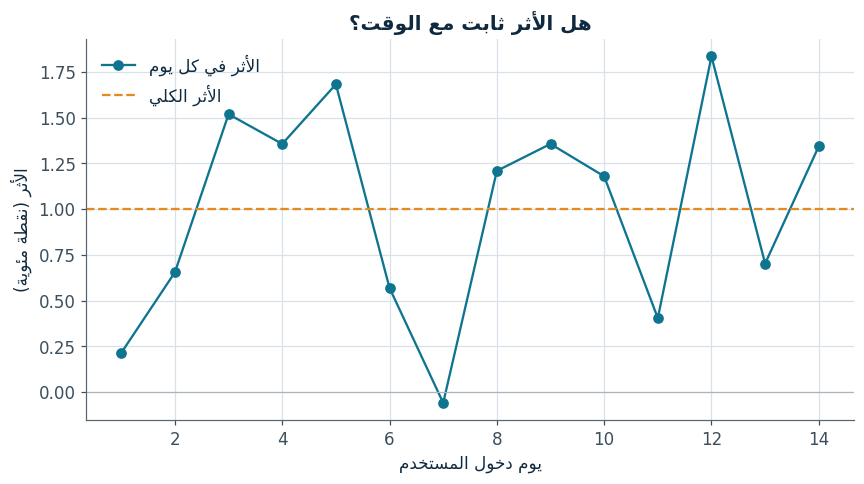

In [9]:
daily = data.groupby(["day", "variant"])["ordered"].mean().unstack()
daily_lift = (daily["B"] - daily["A"]) * 100
plt.plot(daily_lift.index, daily_lift.values, marker="o", color=TEAL, label=ar("الأثر في كل يوم"))
plt.axhline(primary["الفرق"] * 100, color=ORANGE, linestyle="--", label=ar("الأثر الكلي"))
plt.axhline(0, color=GRAY, linewidth=0.8)
plt.xlabel(ar("يوم دخول المستخدم"))
plt.ylabel(ar("الأثر (نقطة مئوية)"))
plt.title(ar("هل الأثر ثابت مع الوقت؟"))
plt.legend()
plt.show()

<div dir="rtl">

**القراءة:** الأثر اليومي يتذبذب بين صفر تقريبًا و1.8 نقطة لأن عينة كل يوم صغيرة (حوالي 5,000 مستخدم)، لكنه موجب في كل الأيام تقريبًا، ولا يظهر هبوط واضح مع الوقت. فلا يوجد دليل قوي على أن الأثر مجرد حداثة، ومع ذلك نتابعه بعد الإطلاق بمجموعة holdout.

</div>

<div dir="rtl">

## 8. (اختياري) إذا لم تستطع إجراء تجربة: الفروق في الفروق

**في مشروعنا لا نحتاج هذا القسم**، لأننا نستطيع عشوأة المستخدمين مباشرة. لكن لو قرر المتجر إطلاق التقييمات في بعض الأقسام (مثل الإلكترونيات) دون غيرها بدون تجربة، فهذه الطريقة تقارن تغير الأقسام التي طُبقت فيها الميزة بتغير الأقسام التي لم تُطبق فيها. الخلية التالية مثال توضيحي بالإعدادات الافتراضية.

</div>

In [10]:
def simulate_policy_panel(n_units=20, n_treated=6, n_periods=24, policy_period=13, effect=8.0, seed=32):
    r = np.random.default_rng(seed)
    level = r.normal(100, 15, n_units)
    shock = r.normal(0, 2, n_periods)
    rows = []
    for i in range(n_units):
        for t in range(1, n_periods + 1):
            treated, post = int(i < n_treated), int(t >= policy_period)
            y = level[i] + 0.8 * t + shock[t - 1] + effect * treated * post + r.normal(0, 3)
            rows.append({"unit": i, "period": t, "treated": treated, "post": post, "y": y})
    df = pd.DataFrame(rows)
    df["treated_post"] = df["treated"] * df["post"]
    return df


policy = simulate_policy_panel()
twfe = smf.ols("y ~ treated_post + C(unit) + C(period)", data=policy).fit(
    cov_type="cluster", cov_kwds={"groups": policy["unit"]})
lo, hi = twfe.conf_int().loc["treated_post"]
say(f"أثر السياسة: {twfe.params['treated_post']:.2f}، وفترة الثقة 95% من {lo:.2f} إلى {hi:.2f}")

<div dir="rtl">

## 9. التقرير والتوصية

الخلية التالية تنشئ تقرير الصفحة الواحدة من نتائج القسم 7. عدّل عدد المستخدمين السنوي حسب مشروعك.

</div>

In [11]:
annual_users = 5_000 * 365              # 5,000 مستخدم جديد يوميًا طوال السنة، حوالي 1.8 مليون
guardrails_ok = all(s == "سليم" for s in guard_status.values())
decision = decide(primary["أدنى 95%"], primary["أعلى 95%"], CONFIG["mde_abs"], guardrails_ok)
profit = guard_table.loc["الربح لكل مستخدم"]
guard_rows = "\n".join(f"| {k} | {v} |" for k, v in guard_status.items())

report = f"""
<div dir="rtl">

### تقرير التجربة: {CONFIG['project']}

**القرار:** {decision}

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الطلب من {A['ordered'].mean():.2%} إلى {B['ordered'].mean():.2%} |
| الأثر | {primary['الفرق'] * 100:.2f} نقطة (فترة الثقة 95%: من {primary['أدنى 95%'] * 100:.2f} إلى {primary['أعلى 95%'] * 100:.2f}) |
| الأثر مع CUPED | {primary_cuped['الفرق'] * 100:.2f} نقطة (من {primary_cuped['أدنى 95%'] * 100:.2f} إلى {primary_cuped['أعلى 95%'] * 100:.2f}) |
| التغير التقديري في الربح السنوي | {profit['الفرق'] * annual_users / 1e6:.2f} مليون ريال (من {profit['أدنى 95%'] * annual_users / 1e6:.2f} إلى {profit['أعلى 95%'] * annual_users / 1e6:.2f}) |

| مقياس الحماية | الحالة |
|---|---|
{guard_rows}

</div>
"""
display(Markdown(report))


<div dir="rtl">

### تقرير التجربة: عرض تقييمات المستخدمين بجانب المنتجات

**القرار:** نطلق، لأن الأثر إيجابي بثقة ومقاييس الحماية سليمة.

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الطلب من 5.73% إلى 6.73% |
| الأثر | 1.00 نقطة (فترة الثقة 95%: من 0.64 إلى 1.36) |
| الأثر مع CUPED | 0.99 نقطة (من 0.63 إلى 1.34) |
| التغير التقديري في الربح السنوي | 0.88 مليون ريال (من 0.56 إلى 1.19) |

| مقياس الحماية | الحالة |
|---|---|
| الربح لكل مستخدم | سليم |
| نسبة إلغاء الطلبات | سليم |
| التواصل مع الدعم | سليم |

</div>


<div dir="rtl">

**توصيتك النهائية والقيود** (من 3 إلى 5 أسطر):

</div>

<div dir="rtl">

- **التوصية:** نطلق عرض التقييمات لكل المستخدمين. رفعت التقييمات نسبة الشراء من 5.73% إلى 6.73%، أي حوالي نقطة مئوية واحدة (فترة الثقة من 0.64 إلى 1.36)، والحد الأدنى للفترة أكبر من صفر وأكبر من أصغر أثر يهمنا (0.6). الإيراد والربح لكل مستخدم ارتفعا، وكل مقاييس الحماية سليمة.
- **الخطوة التالية:** نطلق تدريجيًا (مثلًا 50% ثم 100%) مع إبقاء مجموعة صغيرة بدون تقييمات (holdout) لمدة شهر لنتأكد أن الأثر يستمر بعد زوال الحداثة. ونختبر بعدها طريقة العرض: النجوم فقط، أو النجوم مع عدد المراجعات.
- **القيود:** البيانات من محاكاة، والأثر الحقيقي الذي وضعناه 0.7 نقطة يقع داخل فترة الثقة، لكن التقدير 1.0 أعلى منه قليلًا بسبب العشوائية وأثر الحداثة في الأيام الأولى. لم نقِس سرعة تحميل الصفحة ولا أثر التقييمات السلبية على منتجات بعينها، ونتائج أسبوعين قد لا تمثل مواسم مثل رمضان والجمعة البيضاء.

</div>